# Step 08b: classification, rungs M4 to M6

This notebook fits Naive Bayes, KNN and SVM on the sepsis features with the same protocol as rungs M0 to M3.

## Setup and input checks

Imports, helpers and checks on the files from the earlier steps.

In [1]:
import sys, json, time, warnings, contextlib
from itertools import product
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.naive_bayes import GaussianNB, BernoulliNB
from sklearn.neighbors import NearestNeighbors
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import roc_curve, precision_recall_curve

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
SVM_ROWS = 25_000
SVM_VAL_ROWS = 60_000
RBF_TIME_BUDGET_MIN = 45
KNN_CHUNK = 20_000
SVM_CHUNK = 10_000
RUN_CV = True

sns.set_theme(style="whitegrid")
COL_SEPTIC, COL_CONTROL = "#d1495b", "#2e86ab"
pd.options.display.float_format = "{:.3f}".format
pd.options.display.width = 160
pd.options.display.max_columns = 30

SUMMARY, SAVED, CHECKS = [], [], {"pass": 0, "fail": 0}
SEC = {"t": time.time()}

def log(text=""):
    print(text)
    SUMMARY.append(str(text))

def check(label, ok, detail=""):
    ok = bool(ok)
    CHECKS["pass" if ok else "fail"] += 1
    log(f"[{'PASS' if ok else 'FAIL'}] {label}" + (f" ({detail})" if detail != "" else ""))
    return ok

def expect(label, observed, expected, tol=0):
    return check(label, abs(observed - expected) <= tol, f"observed {observed}, expected {expected}")

@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label + " (exception)", False, f"{type(e).__name__}: {e}")

@contextlib.contextmanager
def timed(label):
    t = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t:.1f} s")

def sec_start():
    SEC["t"] = time.time()

def sec_end(label):
    log(f"[{label}] elapsed {time.time() - SEC['t']:.1f} s")

def need(*names):
    miss = [n for n in names if n not in globals()]
    if miss:
        raise RuntimeError("stopping, earlier sections did not produce: " + ", ".join(miss))

def save_fig(name):
    plt.tight_layout()
    p = FIG / name
    plt.savefig(p, dpi=150)
    SAVED.append(p)
    plt.show()
    plt.close()

def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "dataset").is_dir():
            return q
    raise FileNotFoundError("no folder with a dataset directory above " + str(p))

ROOT = find_root()
PROC, TAB, FIG, SRC = ROOT / "data" / "processed", ROOT / "results" / "tables", ROOT / "results" / "figures", ROOT / "src"
RES = ROOT / "results"
TAB.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

def save_csv(df, name):
    p = TAB / name
    df.to_csv(p, index=False)
    SAVED.append(p)
    return p

def save_parquet(df, name):
    p = PROC / name
    df.to_parquet(p, index=False)
    SAVED.append(p)
    return p

def save_json(obj, name):
    p = PROC / name
    with open(p, "w") as f:
        json.dump(obj, f, indent=2)
    SAVED.append(p)
    return p

def show(df, n=12):
    print(df.head(n).to_string(index=False))

sys.path.insert(0, str(SRC))
import sepsis_eval as ev
log(f"root: {ROOT}")

root: /Users/harnoorkaur/Downloads/Sepsis_ml


In [2]:
sec_start()
FS = json.load(open(PROC / "feature_sets_v2.json"))
CORE, MASKS, PCS = FS["core"], FS["masks_only"], FS["pca_cols"]
IDC = ["patient_id", "hospital", "hour", "split", "SepsisLabel"]
FORBID = set(IDC)
NONFEAT = IDC + ["row_index"]

ff = pd.read_parquet(PROC / "features_flat.parquet", columns=IDC + MASKS)
for c in ["patient_id", "hospital"]:
    ff[c] = ff[c].astype(str)
ps = pd.read_csv(PROC / "patient_splits.csv", dtype={"patient_id": str, "hospital": str})
split = ff["split"].astype(str).to_numpy()
y_all = ff["SepsisLabel"].to_numpy()

with guarded("known sizes"):
    expect("features_flat rows", len(ff), 1_552_210)
    for s, n, p in [("train", 1_085_958, 19_530), ("val", 234_037, 4_183), ("test", 232_215, 4_203)]:
        expect(f"{s} rows", int((split == s).sum()), n)
        expect(f"{s} positive rows", int(y_all[split == s].sum()), p)
    for s, n in [("train", 28_235), ("val", 6_050), ("test", 6_051)]:
        expect(f"{s} patients", int((ps["split"] == s).sum()), n)
    for s, fr, ns in [("val", 65, 5_610), ("test", 63, 5_611)]:
        q = ps[ps["split"] == s]
        ev_ = q["ever_septic"].astype(int)
        expect(f"{s} septic patients", int((ev_ == 1).sum()), 440)
        expect(f"{s} septic patients labelled in first row", int(((ev_ == 1) & (q["first_positive_hour"] == 0)).sum()), fr)
        expect(f"{s} never-septic patients", int((ev_ == 0).sum()), ns)

with guarded("alignment with features_flat"):
    for name in ["core_scaled", "pca_scores"]:
        t = pd.read_parquet(PROC / f"{name}.parquet", columns=["patient_id", "hour"])
        ok = len(t) == len(ff) and (t["patient_id"].astype(str).to_numpy() == ff["patient_id"].to_numpy()).all() \
            and (t["hour"].to_numpy() == ff["hour"].to_numpy()).all()
        check(f"{name} aligned with features_flat on patient_id and hour", ok, f"{len(t):,} rows")
        del t

with guarded("feature lists"):
    expect("core features", len(CORE), 50)
    expect("mask columns", len(MASKS), 34)
    expect("PC columns", len(PCS), 29)
    check("masks are 0/1", set(np.unique(ff[MASKS].to_numpy())) <= {0, 1})
    check("no forbidden column used as a feature", not (FORBID & set(CORE + MASKS + PCS)))

with guarded("training subset"):
    si = pd.read_parquet(PROC / "train_subset_index.parquet")
    ri = si["row_index"].to_numpy()
    expect("subset rows", len(si), 100_000)
    expect("subset positives", int(si["SepsisLabel"].sum()), 19_530)
    check("subset row_index sorted and unique", np.all(np.diff(ri) > 0))
    check("every subset row is a train row", (split[ri] == "train").all())
    check("subset ids and labels match features_flat",
          (ff["patient_id"].to_numpy()[ri] == si["patient_id"].astype(str).to_numpy()).all()
          and (ff["hour"].to_numpy()[ri] == si["hour"].to_numpy()).all()
          and (y_all[ri] == si["SepsisLabel"].to_numpy()).all())
    for fn, feats in [("train_subset_pca", PCS), ("train_subset_core_scaled", CORE)]:
        cols = [c for c in pq.ParquetFile(PROC / f"{fn}.parquet").schema.names if c not in NONFEAT]
        check(f"{fn} feature columns", sorted(cols) == sorted(feats), f"{len(cols)} columns")
    pc_full = pd.read_parquet(PROC / "pca_scores.parquet", columns=PCS).iloc[ri].to_numpy(np.float32)
    sp_chk = pd.read_parquet(PROC / "train_subset_pca.parquet", columns=PCS).to_numpy(np.float32)
    check("subset PCs equal pca_scores at row_index", np.allclose(sp_chk, pc_full))
    del pc_full, sp_chk
sec_end("section 1")

[PASS] features_flat rows (observed 1552210, expected 1552210)
[PASS] train rows (observed 1085958, expected 1085958)
[PASS] train positive rows (observed 19530, expected 19530)
[PASS] val rows (observed 234037, expected 234037)
[PASS] val positive rows (observed 4183, expected 4183)
[PASS] test rows (observed 232215, expected 232215)
[PASS] test positive rows (observed 4203, expected 4203)
[PASS] train patients (observed 28235, expected 28235)
[PASS] val patients (observed 6050, expected 6050)
[PASS] test patients (observed 6051, expected 6051)
[PASS] val septic patients (observed 440, expected 440)
[PASS] val septic patients labelled in first row (observed 65, expected 65)
[PASS] val never-septic patients (observed 5610, expected 5610)
[PASS] test septic patients (observed 440, expected 440)
[PASS] test septic patients labelled in first row (observed 63, expected 63)
[PASS] test never-septic patients (observed 5611, expected 5611)
[PASS] core_scaled aligned with features_flat on pati

## Load data

Train, validation and test tables in float32, plus the fixed training subset.

In [3]:
sec_start()
need("ff", "ps", "split", "y_all", "si")
IDX = {s: np.flatnonzero(split == s) for s in ["train", "val", "test"]}

def load_split_arrays(fn, cols):
    a = pd.read_parquet(PROC / fn, columns=cols).to_numpy(np.float32)
    return {s: a[IDX[s]] for s in IDX}

with timed("load core and pca"):
    XC = load_split_arrays("core_scaled.parquet", CORE)
    XP = load_split_arrays("pca_scores.parquet", PCS)
m_all = ff[MASKS].to_numpy(np.uint8)
XM = {s: m_all[IDX[s]] for s in IDX}
del m_all
XS = {"core": XC, "pca": XP, "mask": XM}
Y = {s: y_all[IDX[s]].astype(np.int32) for s in IDX}
IDS = {s: ff.iloc[IDX[s]][["patient_id", "hour"]].reset_index(drop=True) for s in IDX}

def make_meta(s):
    d = ff.iloc[IDX[s]][["patient_id", "hospital", "hour"]]
    m = d.merge(ps[["patient_id", "hospital", "ever_septic", "first_positive_hour"]], on=["patient_id", "hospital"], how="left")
    return m[["patient_id", "hour", "ever_septic", "first_positive_hour"]].reset_index(drop=True)

META = {s: make_meta(s) for s in ["val", "test"]}

sub_pca = pd.read_parquet(PROC / "train_subset_pca.parquet")
sub_core = pd.read_parquet(PROC / "train_subset_core_scaled.parquet")
SUB_P = sub_pca[PCS].to_numpy(np.float32)
SUB_C = sub_core[CORE].to_numpy(np.float32)
SUB_Y = sub_pca["SepsisLabel"].to_numpy().astype(np.int32)
SUB_ROW = si["row_index"].to_numpy()
del sub_pca, sub_core

with guarded("loaded data"):
    for s in IDX:
        check(f"{s} arrays", len(XC[s]) == len(XP[s]) == len(XM[s]) == len(Y[s]), f"{len(Y[s]):,} rows, {XC[s].shape[1]}/{XP[s].shape[1]}/{XM[s].shape[1]} columns")
    for s in ["val", "test"]:
        check(f"{s} meta length and no missing patients", len(META[s]) == len(Y[s]) and META[s]["ever_septic"].notna().all())
    check("subset arrays", SUB_P.shape == (100_000, 29) and SUB_C.shape == (100_000, 50) and SUB_Y.sum() == 19_530)
    check("subset labels equal in both subset files", (SUB_Y == si["SepsisLabel"].to_numpy()).all())
show(META["val"], 5)
sec_end("section 2")

load core and pca: 0.4 s
[PASS] train arrays (1,085,958 rows, 50/29/34 columns)
[PASS] val arrays (234,037 rows, 50/29/34 columns)
[PASS] test arrays (232,215 rows, 50/29/34 columns)
[PASS] val meta length and no missing patients
[PASS] test meta length and no missing patients
[PASS] subset arrays
[PASS] subset labels equal in both subset files
patient_id  hour  ever_septic  first_positive_hour
   p000003     0        False                  NaN
   p000003     1        False                  NaN
   p000003     2        False                  NaN
   p000003     3        False                  NaN
   p000003     4        False                  NaN
[section 2] elapsed 0.8 s


## M4, Naive Bayes

Three Naive Bayes variants are fitted on all train rows and tuned on validation AUPRC. The score is the log-odds, because the predicted probabilities saturate and create ties.

In [4]:
sec_start()
need("XS", "Y", "META")

def nb_score(m, X):
    lp = m.predict_log_proba(X)
    return (lp[:, 1] - lp[:, 0]).astype(np.float32)

NB_SPEC = {
    "M4_gnb_core": dict(key="core", nfeat=50, pname="var_smoothing", grid=np.logspace(-9, -1, 9), make=lambda v: GaussianNB(var_smoothing=v)),
    "M4b_bnb_masks": dict(key="mask", nfeat=34, pname="alpha", grid=[0.01, 0.1, 0.5, 1, 2, 5], make=lambda v: BernoulliNB(alpha=v, binarize=None)),
    "M4c_gnb_pca": dict(key="pca", nfeat=29, pname="var_smoothing", grid=np.logspace(-9, -1, 9), make=lambda v: GaussianNB(var_smoothing=v)),
}
NB, nb_rows = {}, []
for name, sp_ in NB_SPEC.items():
    X, best = XS[sp_["key"]], None
    for v in tqdm(sp_["grid"], desc=name):
        m = sp_["make"](v).fit(X["train"], Y["train"])
        s = nb_score(m, X["val"])
        cm = ev.curve_metrics(Y["val"], s)
        nb_rows.append(dict(variant=name, parameter=sp_["pname"], value=float(v), val_auprc=cm["auprc"], val_auroc=cm["auroc"]))
        if best is None or cm["auprc"] > best["auprc"]:
            best = dict(model=m, value=float(v), score=s, auprc=cm["auprc"], auroc=cm["auroc"])
    NB[name] = best
    log(f"{name}: best {sp_['pname']} = {best['value']:.3g}, val auprc {best['auprc']:.3f}, val auroc {best['auroc']:.3f}, distinct val scores {np.unique(best['score']).size:,}")
nb_tune = pd.DataFrame(nb_rows)
save_csv(nb_tune, "m4_nb_tuning.csv")
show(nb_tune.sort_values("val_auprc", ascending=False), 12)

M4_gnb_core: 100%|██████████| 9/9 [00:03<00:00,  2.79it/s]


M4_gnb_core: best var_smoothing = 0.01, val auprc 0.081, val auroc 0.742, distinct val scores 226,961


M4b_bnb_masks: 100%|██████████| 6/6 [00:03<00:00,  1.68it/s]


M4b_bnb_masks: best alpha = 5, val auprc 0.026, val auroc 0.584, distinct val scores 7,062


M4c_gnb_pca: 100%|██████████| 9/9 [00:02<00:00,  3.22it/s]

M4c_gnb_pca: best var_smoothing = 0.1, val auprc 0.077, val auroc 0.774, distinct val scores 197,709
    variant     parameter  value  val_auprc  val_auroc
M4_gnb_core var_smoothing  0.010      0.081      0.742
M4_gnb_core var_smoothing  0.000      0.081      0.743
M4_gnb_core var_smoothing  0.000      0.081      0.743
M4_gnb_core var_smoothing  0.000      0.081      0.743
M4_gnb_core var_smoothing  0.000      0.081      0.743
M4_gnb_core var_smoothing  0.000      0.081      0.743
M4_gnb_core var_smoothing  0.001      0.081      0.743
M4_gnb_core var_smoothing  0.000      0.081      0.743
M4_gnb_core var_smoothing  0.100      0.081      0.740
M4c_gnb_pca var_smoothing  0.100      0.077      0.774
M4c_gnb_pca var_smoothing  0.010      0.064      0.754
M4c_gnb_pca var_smoothing  0.001      0.061      0.745


feature_set  n_features  n_pairs  mean_abs_corr  share_pairs_abs_r_above_0_5
       core          50     1225          0.199                        0.118
        pca          29      406          0.003                        0.000


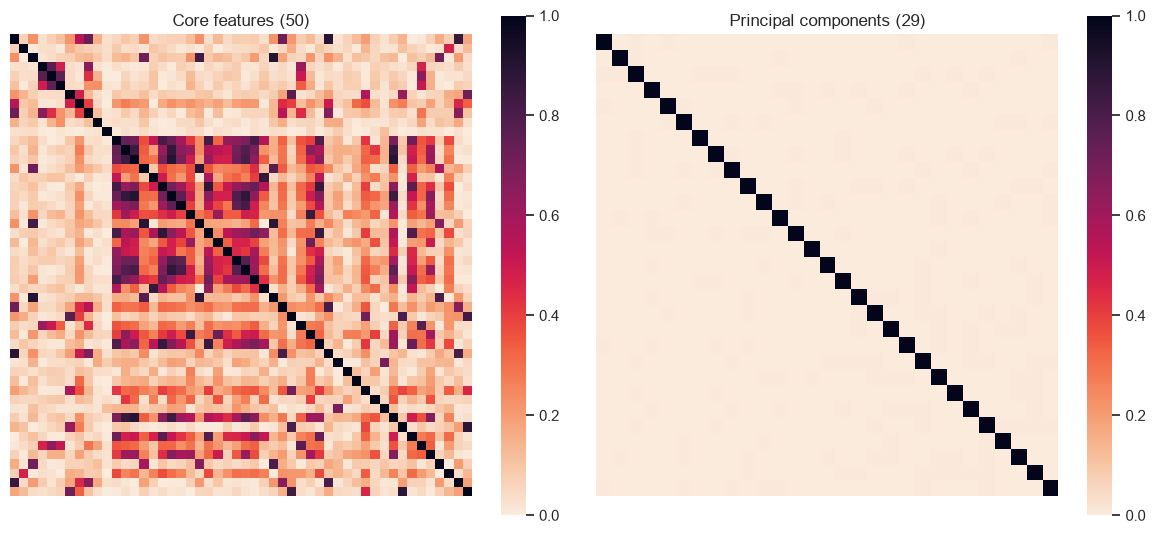

[section 3] elapsed 10.0 s


In [5]:
rng = np.random.default_rng(SEED)
ci = rng.choice(len(XC["train"]), 100_000, replace=False)

def corr_stats(X):
    r = np.abs(np.corrcoef(X[ci].astype(np.float64), rowvar=False))
    iu = np.triu_indices_from(r, k=1)
    return r, float(np.nanmean(r[iu])), float(np.mean(r[iu] > 0.5)), len(iu[0])

r_core, mc, sc, nc = corr_stats(XC["train"])
r_pc, mp, sp2, npair = corr_stats(XP["train"])
corr_df = pd.DataFrame([
    dict(feature_set="core", n_features=50, n_pairs=nc, mean_abs_corr=mc, share_pairs_abs_r_above_0_5=sc),
    dict(feature_set="pca", n_features=29, n_pairs=npair, mean_abs_corr=mp, share_pairs_abs_r_above_0_5=sp2),
])
save_csv(corr_df, "m4_nb_correlation_summary.csv")
show(corr_df)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
for ax, r, ttl in zip(axs, [r_core, r_pc], ["Core features (50)", "Principal components (29)"]):
    sns.heatmap(r, vmin=0, vmax=1, cmap="rocket_r", square=True, xticklabels=False, yticklabels=False, annot=False, ax=ax)
    ax.set_title(ttl)
save_fig("fig08b_nb_correlation.png")
del r_core, r_pc
sec_end("section 3")

## M5, KNN

The reference set is the training subset in PC space. Neighbours of the validation rows are found once and the scores for all eight settings come from them.

In [6]:
sec_start()
need("SUB_P", "SUB_C", "SUB_Y", "XP", "XC", "Y")
K_GRID, W_GRID, K_MAX = [5, 15, 31, 51], ["uniform", "distance"], 51

def knn_search(nn, X, desc):
    n = len(X)
    idx, dist = np.empty((n, K_MAX), np.int32), np.empty((n, K_MAX), np.float32)
    for a in tqdm(range(0, n, KNN_CHUNK), desc=desc):
        b = min(a + KNN_CHUNK, n)
        d, i = nn.kneighbors(X[a:b])
        idx[a:b], dist[a:b] = i, d
    return idx, dist

def knn_score(idx, dist, labels, k, w):
    lab = labels[idx[:, :k]].astype(np.float32)
    if w == "uniform":
        return lab.mean(axis=1)
    wt = 1.0 / (dist[:, :k] + 1e-6)
    return (lab * wt).sum(axis=1) / wt.sum(axis=1)

t0 = time.time()
nn_pca = NearestNeighbors(n_neighbors=K_MAX, algorithm="brute", n_jobs=-1).fit(SUB_P)
nb_idx, nb_dist = knn_search(nn_pca, XP["val"], "val neighbours (pca)")
sec_pca = time.time() - t0
log(f"pca knn fit and val search: {sec_pca:.1f} s")

with guarded("val neighbour arrays"):
    check("neighbour shapes and dtypes", nb_idx.shape == (len(XP["val"]), K_MAX) and nb_dist.shape == nb_idx.shape and nb_idx.dtype == np.int32 and nb_dist.dtype == np.float32, str(nb_idx.shape))
    check("neighbour indices inside the subset", nb_idx.min() >= 0 and nb_idx.max() < len(SUB_P))
    check("distances sorted", np.all(np.diff(nb_dist[:2000], axis=1) >= -1e-5))

rows = []
for k, w in product(K_GRID, W_GRID):
    cm = ev.curve_metrics(Y["val"], knn_score(nb_idx, nb_dist, SUB_Y, k, w))
    rows.append(dict(k=k, weights=w, val_auprc=cm["auprc"], val_auroc=cm["auroc"]))
knn_tune = pd.DataFrame(rows)
save_csv(knn_tune, "m5_knn_tuning.csv")
show(knn_tune.sort_values("val_auprc", ascending=False))
bk = knn_tune.sort_values("val_auprc", ascending=False).iloc[0]
BEST_K, BEST_W = int(bk["k"]), str(bk["weights"])
KNN_VAL = knn_score(nb_idx, nb_dist, SUB_Y, BEST_K, BEST_W)
log(f"M5 best: k = {BEST_K}, weights = {BEST_W}, val auprc {bk['val_auprc']:.3f}, distinct val scores {np.unique(KNN_VAL).size:,}")
del nb_idx, nb_dist

val neighbours (pca): 100%|██████████| 12/12 [00:21<00:00,  1.81s/it]


pca knn fit and val search: 21.8 s
[PASS] neighbour shapes and dtypes ((234037, 51))
[PASS] neighbour indices inside the subset
[PASS] distances sorted
 k  weights  val_auprc  val_auroc
51 distance      0.081      0.787
51  uniform      0.080      0.788
31 distance      0.074      0.774
31  uniform      0.073      0.775
15 distance      0.063      0.750
15  uniform      0.061      0.751
 5 distance      0.045      0.689
 5  uniform      0.043      0.688
M5 best: k = 51, weights = distance, val auprc 0.081, distinct val scores 175,584


In [7]:
t0 = time.time()
nn_core = NearestNeighbors(n_neighbors=K_MAX, algorithm="brute", n_jobs=-1).fit(SUB_C)
c_idx, c_dist = knn_search(nn_core, XC["val"], "val neighbours (core)")
sec_core = time.time() - t0
cm = ev.curve_metrics(Y["val"], knn_score(c_idx, c_dist, SUB_Y, BEST_K, BEST_W))
pca_row = knn_tune[(knn_tune["k"] == BEST_K) & (knn_tune["weights"] == BEST_W)].iloc[0]
cmp_df = pd.DataFrame([
    dict(variant="pca_29", k=BEST_K, weights=BEST_W, val_auroc=pca_row["val_auroc"], val_auprc=pca_row["val_auprc"], seconds=sec_pca),
    dict(variant="core_50", k=BEST_K, weights=BEST_W, val_auroc=cm["auroc"], val_auprc=cm["auprc"], seconds=sec_core),
])
save_csv(cmp_df, "m5_knn_pca_vs_core.csv")
show(cmp_df)
del nn_core, c_idx, c_dist
sec_end("section 4")

val neighbours (core): 100%|██████████| 12/12 [00:29<00:00,  2.48s/it]


variant  k  weights  val_auroc  val_auprc  seconds
 pca_29 51 distance      0.787      0.081   21.767
core_50 51 distance      0.793      0.084   29.720
[section 4] elapsed 52.6 s


## M6, SVM

A linear SVM uses all 100,000 subset rows and an RBF SVM uses a random 25,000 of them. Both work on the PCs.

In [8]:
sec_start()
need("SUB_P", "SUB_Y", "XP", "Y", "SUB_ROW", "IDX")

def chunked_decision(m, X, desc):
    out = np.empty(len(X), np.float32)
    for a in tqdm(range(0, len(X), SVM_CHUNK), desc=desc):
        out[a:a + SVM_CHUNK] = m.decision_function(X[a:a + SVM_CHUNK])
    return out

svm_rows, best_lin = [], None
for C in tqdm([0.001, 0.01, 0.1, 1, 10], desc="linear svm"):
    t = time.time()
    m = LinearSVC(C=C, class_weight="balanced", dual=False, max_iter=2000, random_state=SEED).fit(SUB_P, SUB_Y)
    fit_s = time.time() - t
    t = time.time()
    s = m.decision_function(XP["val"]).astype(np.float32)
    score_s = time.time() - t
    cm = ev.curve_metrics(Y["val"], s)
    svm_rows.append(dict(kernel="linear", C=C, gamma=np.nan, val_auprc=cm["auprc"], val_auroc=cm["auroc"], fit_s=fit_s, score_s=score_s, n_support=np.nan))
    if best_lin is None or cm["auprc"] > best_lin["auprc"]:
        best_lin = dict(model=m, C=C, score=s, auprc=cm["auprc"], auroc=cm["auroc"])
LIN_MODEL, LIN_VAL = best_lin["model"], best_lin["score"]
log(f"M6_linsvm: best C = {best_lin['C']}, val auprc {best_lin['auprc']:.3f}, val auroc {best_lin['auroc']:.3f}")
show(pd.DataFrame(svm_rows))

linear svm: 100%|██████████| 5/5 [00:02<00:00,  2.44it/s]

M6_linsvm: best C = 0.001, val auprc 0.074, val auroc 0.770
kernel      C  gamma  val_auprc  val_auroc  fit_s  score_s  n_support
linear  0.001    NaN      0.074      0.770  0.239    0.028        NaN
linear  0.010    NaN      0.074      0.770  0.213    0.006        NaN
linear  0.100    NaN      0.074      0.770  0.244    0.007        NaN
linear  1.000    NaN      0.074      0.770  0.329    0.012        NaN
linear 10.000    NaN      0.074      0.770  0.363    0.012        NaN


In [9]:
rng = np.random.default_rng(SEED)
svm_pos = np.sort(rng.choice(len(SUB_Y), SVM_ROWS, replace=False))
svm_val_pos = np.sort(rng.choice(len(Y["val"]), SVM_VAL_ROWS, replace=False))
with guarded("svm training rows"):
    sel = SUB_ROW[svm_pos]
    check("SVM_ROWS rows are a subset of the train subset", len(np.unique(sel)) == SVM_ROWS and np.isin(sel, SUB_ROW).all() and np.isin(sel, IDX["train"]).all(), f"{SVM_ROWS:,} rows")
Xr, yr = SUB_P[svm_pos], SUB_Y[svm_pos]
Xv_t, yv_t = XP["val"][svm_val_pos], Y["val"][svm_val_pos]

best_rbf, t_tune = None, time.time()
grid = list(product([0.3, 1, 3], [0.01, 0.05]))
for C, g in tqdm(grid, desc="rbf svm"):
    if best_rbf is not None and time.time() - t_tune > RBF_TIME_BUDGET_MIN * 60:
        log(f"rbf time budget of {RBF_TIME_BUDGET_MIN} min reached, remaining configurations skipped")
        break
    t = time.time()
    m = SVC(kernel="rbf", C=C, gamma=g, class_weight="balanced", cache_size=2000, random_state=SEED).fit(Xr, yr)
    fit_s = time.time() - t
    t = time.time()
    s = m.decision_function(Xv_t).astype(np.float32)
    score_s = time.time() - t
    cm = ev.curve_metrics(yv_t, s)
    nsv = int(m.n_support_.sum())
    svm_rows.append(dict(kernel="rbf", C=C, gamma=g, val_auprc=cm["auprc"], val_auroc=cm["auroc"], fit_s=fit_s, score_s=score_s, n_support=nsv))
    log(f"rbf C={C}, gamma={g}: val auprc {cm['auprc']:.3f}, auroc {cm['auroc']:.3f}, fit {fit_s:.0f} s, score {score_s:.0f} s, support vectors {nsv:,}")
    if best_rbf is None or cm["auprc"] > best_rbf["auprc"]:
        best_rbf = dict(model=m, C=C, gamma=g, auprc=cm["auprc"], auroc=cm["auroc"])
    del m
if best_rbf is None:
    raise RuntimeError("no rbf configuration was fitted")
svm_tune = pd.DataFrame(svm_rows)
save_csv(svm_tune, "m6_svm_tuning.csv")
RBF_MODEL = best_rbf["model"]
log(f"M6_rbfsvm: best C = {best_rbf['C']}, gamma = {best_rbf['gamma']}")
with timed("rbf scoring on full val"):
    RBF_VAL = chunked_decision(RBF_MODEL, XP["val"], "rbf full val")
cl, cr = ev.curve_metrics(Y["val"], LIN_VAL), ev.curve_metrics(Y["val"], RBF_VAL)
log(f"full val auprc: linear {cl['auprc']:.3f}, rbf {cr['auprc']:.3f} (auroc: linear {cl['auroc']:.3f}, rbf {cr['auroc']:.3f})")
del Xr, yr, Xv_t, yv_t
sec_end("section 5")

[PASS] SVM_ROWS rows are a subset of the train subset (25,000 rows)


rbf svm:  17%|█▋        | 1/6 [01:16<06:20, 76.01s/it]

rbf C=0.3, gamma=0.01: val auprc 0.077, auroc 0.806, fit 17 s, score 59 s, support vectors 15,195


rbf svm:  33%|███▎      | 2/6 [02:33<05:08, 77.03s/it]

rbf C=0.3, gamma=0.05: val auprc 0.069, auroc 0.803, fit 16 s, score 62 s, support vectors 15,810


rbf svm:  50%|█████     | 3/6 [03:46<03:44, 74.89s/it]

... (5 outputs left out)

rbf svm: 100%|██████████| 6/6 [07:08<00:00, 71.39s/it]


rbf C=3, gamma=0.05: val auprc 0.054, auroc 0.765, fit 14 s, score 50 s, support vectors 13,068
M6_rbfsvm: best C = 0.3, gamma = 0.01


rbf full val: 100%|██████████| 24/24 [03:20<00:00,  8.33s/it]

rbf scoring on full val: 200.0 s
full val auprc: linear 0.074, rbf 0.078 (auroc: linear 0.770, rbf 0.808)
[section 5] elapsed 630.6 s


## Thresholds and evaluation of the six models

Thresholds are chosen on the full validation scores and written to file before any test row is scored.

In [10]:
sec_start()
need("NB", "KNN_VAL", "LIN_VAL", "RBF_VAL", "nn_pca", "LIN_MODEL", "RBF_MODEL", "META", "BEST_K", "BEST_W")
MODELS = [("M4_gnb_core", 50), ("M4b_bnb_masks", 34), ("M4c_gnb_pca", 29), ("M5_knn", 29), ("M6_linsvm", 29), ("M6_rbfsvm", 29)]
VAL = {"M4_gnb_core": NB["M4_gnb_core"]["score"], "M4b_bnb_masks": NB["M4b_bnb_masks"]["score"], "M4c_gnb_pca": NB["M4c_gnb_pca"]["score"],
       "M5_knn": KNN_VAL, "M6_linsvm": LIN_VAL, "M6_rbfsvm": RBF_VAL}
with guarded("val scores"):
    for m_, _ in MODELS:
        check(f"{m_} val scores finite and right length", np.isfinite(VAL[m_]).all() and len(VAL[m_]) == len(Y["val"]), f"{len(VAL[m_]):,} rows")

THR = {m_: float(ev.best_f2_threshold(Y["val"], VAL[m_])) for m_, _ in MODELS}
thr_path = save_json(THR, "thresholds_m4_m6.json")
T_THR = thr_path.stat().st_mtime
for m_, t_ in THR.items():
    log(f"threshold {m_}: {t_:.4f}")
check("thresholds file written", thr_path.exists() and json.load(open(thr_path)) == THR)

[PASS] M4_gnb_core val scores finite and right length (234,037 rows)
[PASS] M4b_bnb_masks val scores finite and right length (234,037 rows)
[PASS] M4c_gnb_pca val scores finite and right length (234,037 rows)
[PASS] M5_knn val scores finite and right length (234,037 rows)
[PASS] M6_linsvm val scores finite and right length (234,037 rows)
[PASS] M6_rbfsvm val scores finite and right length (234,037 rows)
threshold M4_gnb_core: 12.4233
threshold M4b_bnb_masks: -3.9310
threshold M4c_gnb_pca: -3.9768
threshold M5_knn: 0.3782
threshold M6_linsvm: 0.3790
threshold M6_rbfsvm: 0.7127
[PASS] thresholds file written


True

In [11]:
def result_row(name, nfeat, y, s, thr):
    r = {"model": name, "n_features": nfeat, "threshold": thr}
    r.update(ev.row_metrics(y, s, thr))
    r.update(ev.curve_metrics(y, s))
    return r

COUNTS = ["tp", "fp", "tn", "fn"]
res_val_full = pd.DataFrame([result_row(m_, n_, Y["val"], VAL[m_], THR[m_]) for m_, n_ in MODELS])
res_val = res_val_full.drop(columns=COUNTS)
save_csv(res_val, "m4_m6_results_val.csv")
log("val metrics at a threshold tuned on val are optimistic")
show(res_val[["model", "threshold", "sensitivity", "specificity", "precision", "f2", "auroc", "auprc"]])

def alert_table(meta, scores):
    out = []
    for m_, _ in MODELS:
        d = {"model": m_}
        d.update(ev.alert_metrics(meta, scores[m_], THR[m_]))
        out.append(d)
    return pd.DataFrame(out)

AM_VAL = alert_table(META["val"], VAL)
save_csv(AM_VAL, "m4_m6_alert_metrics_val.csv")
show(AM_VAL[["model", "n_early", "share_alerted_by_first_label", "share_alerted_any", "median_lead_h", "share_nonseptic_ever_alerted", "false_alert_episodes_per_100_patient_days"]])

sweep = []
for m_, _ in tqdm(MODELS, desc="val threshold sweep"):
    s = VAL[m_]
    th = np.quantile(s, np.linspace(0.05, 0.95, 15)).astype(np.float64)
    sw = ev.sweep_thresholds(Y["val"], s, th)[["threshold", "sensitivity", "specificity", "precision", "f1", "f2"]].reset_index(drop=True)
    am = [ev.alert_metrics(META["val"], s, t_) for t_ in th]
    sw["share_alerted_by_first_label"] = [a["share_alerted_by_first_label"] for a in am]
    sw["false_alert_episodes_per_100_patient_days"] = [a["false_alert_episodes_per_100_patient_days"] for a in am]
    sw.insert(0, "model", m_)
    sweep.append(sw)
sweep = pd.concat(sweep, ignore_index=True)
save_csv(sweep, "m4_m6_threshold_sweep_val.csv")
show(sweep, 15)

val metrics at a threshold tuned on val are optimistic
        model  threshold  sensitivity  specificity  precision    f2  auroc  auprc
  M4_gnb_core     12.423        0.361        0.944      0.105 0.243  0.742  0.081
M4b_bnb_masks     -3.931        0.394        0.791      0.033 0.124  0.584  0.026
  M4c_gnb_pca     -3.977        0.424        0.922      0.090 0.243  0.774  0.077
       M5_knn      0.378        0.384        0.933      0.095 0.239  0.787  0.081
    M6_linsvm      0.379        0.400        0.923      0.087 0.232  0.770  0.074
    M6_rbfsvm      0.713        0.495        0.899      0.082 0.247  0.808  0.078
        model  n_early  share_alerted_by_first_label  share_alerted_any  median_lead_h  share_nonseptic_ever_alerted  false_alert_episodes_per_100_patient_days
  M4_gnb_core      375                         0.411              0.472         38.000                         0.052                                     10.578
M4b_bnb_masks      375                         0.90

val threshold sweep: 100%|██████████| 6/6 [00:05<00:00,  1.08it/s]

      model  threshold  sensitivity  specificity  precision    f1    f2  share_alerted_by_first_label  false_alert_episodes_per_100_patient_days
M4_gnb_core    -21.962        0.986        0.051      0.019 0.036 0.086                         0.995                                    415.022
M4_gnb_core    -20.333        0.964        0.116      0.019 0.038 0.090                         0.995                                    395.841
M4_gnb_core    -19.358        0.935        0.181      0.020 0.040 0.094                         0.957                                    358.727
M4_gnb_core    -18.106        0.905        0.246      0.021 0.042 0.098                         0.923                                    328.888
M4_gnb_core    -16.795        0.879        0.311      0.023 0.044 0.103                         0.896                                    301.381
M4_gnb_core    -15.517        0.847        0.375      0.024 0.047 0.108                         0.883                             

In [12]:
T_TEST = time.time()
check("thresholds file written before test scoring", T_THR < T_TEST)
TEST = {}
with timed("test scoring"):
    for name, sp_ in NB_SPEC.items():
        TEST[name] = nb_score(NB[name]["model"], XS[sp_["key"]]["test"])
    t_idx, t_dist = knn_search(nn_pca, XP["test"], "test neighbours")
    with guarded("test neighbour arrays"):
        check("test neighbour shapes", t_idx.shape == (len(XP["test"]), K_MAX) and t_dist.shape == t_idx.shape and t_idx.dtype == np.int32 and t_dist.dtype == np.float32, str(t_idx.shape))
    TEST["M5_knn"] = knn_score(t_idx, t_dist, SUB_Y, BEST_K, BEST_W)
    TEST["M6_linsvm"] = chunked_decision(LIN_MODEL, XP["test"], "linear test")
    TEST["M6_rbfsvm"] = chunked_decision(RBF_MODEL, XP["test"], "rbf test")
log("test scored once")
del t_idx, t_dist
for d in (XC, XP, XM):
    d.pop("test", None)

yt = Y["test"]
res_test = pd.DataFrame([result_row(m_, n_, yt, TEST[m_], THR[m_]) for m_, n_ in MODELS])
save_csv(res_test, "m4_m6_results_test.csv")
AM_TEST = alert_table(META["test"], TEST)
save_csv(AM_TEST, "m4_m6_alert_metrics_test.csv")
show(res_test[["model", "threshold", "sensitivity", "specificity", "precision", "f2", "accuracy", "auroc", "auprc"]])
show(AM_TEST[["model", "n_early", "share_alerted_by_first_label", "share_alerted_any", "median_lead_h", "share_nonseptic_ever_alerted", "false_alert_episodes_per_100_patient_days"]])
acc0 = 1 - float(yt.mean())
log(f"test accuracy of always predicting 0: {acc0:.4f}; models: " + ", ".join(f"{r.model} {r.accuracy:.4f}" for r in res_test.itertuples()))

[PASS] thresholds file written before test scoring


test neighbours: 100%|██████████| 12/12 [00:08<00:00,  1.39it/s]


[PASS] test neighbour shapes ((232215, 51))


rbf test: 100%|██████████| 24/24 [02:09<00:00,  5.41s/it]


test scoring: 138.5 s
test scored once
        model  threshold  sensitivity  specificity  precision    f2  accuracy  auroc  auprc
  M4_gnb_core     12.423        0.353        0.948      0.111 0.246     0.937  0.757  0.082
M4b_bnb_masks     -3.931        0.395        0.800      0.035 0.130     0.793  0.594  0.027
  M4c_gnb_pca     -3.977        0.420        0.922      0.091 0.243     0.913  0.788  0.077
       M5_knn      0.378        0.379        0.938      0.101 0.244     0.928  0.793  0.083
    M6_linsvm      0.379        0.378        0.925      0.085 0.223     0.915  0.776  0.077
    M6_rbfsvm      0.713        0.474        0.906      0.085 0.247     0.898  0.813  0.081
        model  n_early  share_alerted_by_first_label  share_alerted_any  median_lead_h  share_nonseptic_ever_alerted  false_alert_episodes_per_100_patient_days
  M4_gnb_core      377                         0.385              0.467         39.000                         0.047                                      9.9

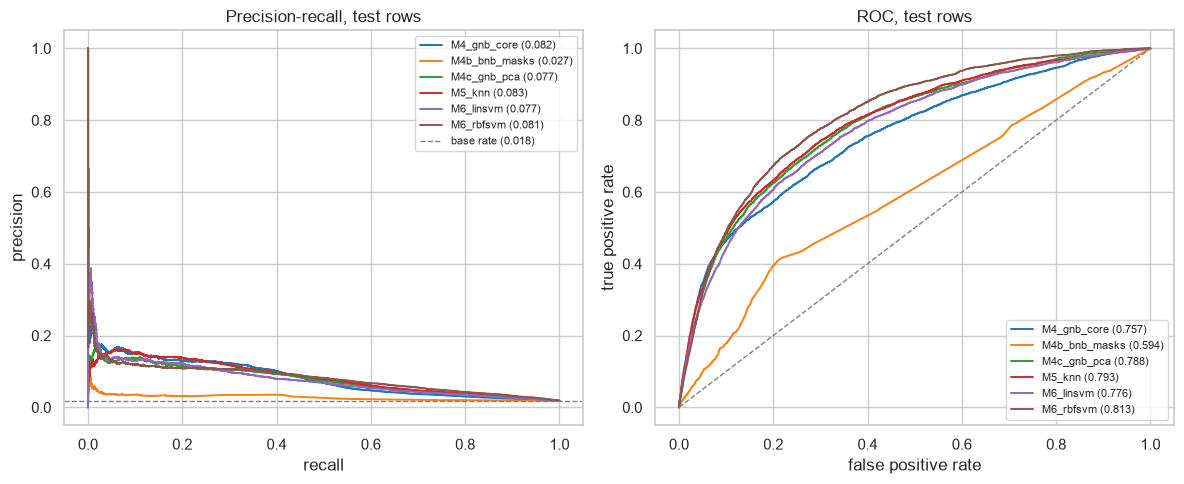

In [13]:
cols = [m_ for m_, _ in MODELS]
sv = IDS["val"].copy(); sv["SepsisLabel"] = Y["val"]
st = IDS["test"].copy(); st["SepsisLabel"] = yt
for m_ in cols:
    sv[m_] = VAL[m_].astype(np.float32)
    st[m_] = TEST[m_].astype(np.float32)
save_parquet(sv, "scores_m4_m6_val.parquet")
save_parquet(st, "scores_m4_m6_test.parquet")
del sv, st

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
pal = sns.color_palette("tab10", len(cols))
for c, m_ in zip(pal, cols):
    p, r, _ = precision_recall_curve(yt, TEST[m_])
    axs[0].plot(r, p, color=c, lw=1.4, label=f"{m_} ({res_test.set_index('model').loc[m_, 'auprc']:.3f})")
    f, t, _ = roc_curve(yt, TEST[m_])
    axs[1].plot(f, t, color=c, lw=1.4, label=f"{m_} ({res_test.set_index('model').loc[m_, 'auroc']:.3f})")
axs[0].axhline(yt.mean(), color="grey", ls="--", lw=1, label=f"base rate ({yt.mean():.3f})")
axs[1].plot([0, 1], [0, 1], color="grey", ls="--", lw=1)
axs[0].set(xlabel="recall", ylabel="precision", title="Precision-recall, test rows")
axs[1].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC, test rows")
axs[0].legend(fontsize=8); axs[1].legend(fontsize=8)
save_fig("fig08b_pr_roc_test.png")

In [14]:
with guarded("section 6 checks"):
    for nm, sc, n in [("val", VAL, len(Y["val"])), ("test", TEST, len(yt))]:
        check(f"{nm} scores finite and of the right length", all(np.isfinite(sc[m_]).all() and len(sc[m_]) == n for m_ in cols), f"{n:,} rows")
    for nm, am, fr, ns in [("val", AM_VAL, 65, 5_610), ("test", AM_TEST, 63, 5_611)]:
        check(f"{nm} early + first-row septic patients = 440", ((am["n_early"] + am["n_first_row"]) == 440).all())
        check(f"{nm} first-row patients = {fr}", (am["n_first_row"] == fr).all())
        check(f"{nm} never-septic patients = {ns}", (am["n_nonseptic"] == ns).all())
    check("val confusion matrices sum to the row count", ((res_val_full[COUNTS].sum(axis=1)) == len(Y["val"])).all())
    check("test confusion matrices sum to the row count", ((res_test[COUNTS].sum(axis=1)) == len(yt)).all())
    check("no val AUROC above 0.95", (res_val["auroc"] <= 0.95).all(), f"max {res_val['auroc'].max():.3f}")
    check("no test AUROC above 0.95", (res_test["auroc"] <= 0.95).all(), f"max {res_test['auroc'].max():.3f}")
sec_end("section 6")

[PASS] val scores finite and of the right length (234,037 rows)
[PASS] test scores finite and of the right length (232,215 rows)
[PASS] val early + first-row septic patients = 440
[PASS] val first-row patients = 65
[PASS] val never-septic patients = 5610
[PASS] test early + first-row septic patients = 440
[PASS] test first-row patients = 63
[PASS] test never-septic patients = 5611
[PASS] val confusion matrices sum to the row count
[PASS] test confusion matrices sum to the row count
[PASS] no val AUROC above 0.95 (max 0.808)
[PASS] no test AUROC above 0.95 (max 0.813)
[section 6] elapsed 146.2 s


## Cross-validation of M4

Each Naive Bayes variant is refitted on four of the five patient folds of train and val and scored on the fifth.

In [15]:
sec_start()
if not RUN_CV:
    log("cross-validation skipped (RUN_CV is False)")
else:
    need("NB", "NB_SPEC", "XS", "Y", "ps")
    def fold_of(s):
        d = ff.iloc[IDX[s]][["patient_id", "hospital"]]
        return d.merge(ps[["patient_id", "hospital", "cv_fold"]], on=["patient_id", "hospital"], how="left")["cv_fold"].to_numpy()
    fold = np.concatenate([fold_of("train"), fold_of("val")])
    yall = np.concatenate([Y["train"], Y["val"]])
    with guarded("cv folds"):
        check("every train and val row has a fold from 0 to 4", np.isin(fold, range(5)).all(), f"{len(fold):,} rows")
    fold = fold.astype(int)
    cv_rows = []
    for name, sp_ in NB_SPEC.items():
        Xa = np.concatenate([XS[sp_["key"]]["train"], XS[sp_["key"]]["val"]])
        for f in tqdm(range(5), desc=f"cv {name}"):
            te = fold == f
            m = sp_["make"](NB[name]["value"]).fit(Xa[~te], yall[~te])
            cm = ev.curve_metrics(yall[te], nb_score(m, Xa[te]))
            cv_rows.append(dict(model=name, fold=f, auroc=cm["auroc"], auprc=cm["auprc"]))
        del Xa
    cv = pd.DataFrame(cv_rows)
    save_csv(cv, "m4_cv_results.csv")
    cv_sum = cv.groupby("model").agg(auroc_mean=("auroc", "mean"), auroc_std=("auroc", "std"), auprc_mean=("auprc", "mean"), auprc_std=("auprc", "std")).reset_index()
    save_csv(cv_sum, "m4_cv_summary.csv")
    show(cv_sum)
    log("KNN and SVM are not cross-validated: they are trained on a fixed train-only subset and tuned on the train-to-validation split")
    log("the PCA and the scaling were fitted on train rows, which include some of the held-out patients in these folds")
sec_end("section 7")

[PASS] every train and val row has a fold from 0 to 4 (1,319,995 rows)


cv M4c_gnb_pca: 100%|██████████| 5/5 [00:00<00:00,  5.39it/s]

        model  auroc_mean  auroc_std  auprc_mean  auprc_std
  M4_gnb_core       0.749      0.015       0.079      0.011
M4b_bnb_masks       0.587      0.009       0.026      0.001
  M4c_gnb_pca       0.778      0.011       0.075      0.010
KNN and SVM are not cross-validated: they are trained on a fixed train-only subset and tuned on the train-to-validation split
the PCA and the scaling were fitted on train rows, which include some of the held-out patients in these folds
[section 7] elapsed 4.4 s


## Output files

Every saved file is listed with its size, followed by the check count and the written log.

In [16]:
sec_start()
expected = [TAB / n for n in ["m4_nb_tuning.csv", "m4_nb_correlation_summary.csv", "m5_knn_tuning.csv", "m5_knn_pca_vs_core.csv", "m6_svm_tuning.csv",
            "m4_m6_results_val.csv", "m4_m6_alert_metrics_val.csv", "m4_m6_threshold_sweep_val.csv", "m4_m6_results_test.csv", "m4_m6_alert_metrics_test.csv"]]
expected += [FIG / "fig08b_nb_correlation.png", FIG / "fig08b_pr_roc_test.png"]
expected += [PROC / n for n in ["thresholds_m4_m6.json", "scores_m4_m6_val.parquet", "scores_m4_m6_test.parquet"]]
if RUN_CV:
    expected += [TAB / "m4_cv_results.csv", TAB / "m4_cv_summary.csv"]
for p in expected:
    if p.exists():
        log(f"{p.relative_to(ROOT)}: {p.stat().st_size / 1e6:.2f} MB")
    else:
        check(f"{p.name} exists", False, "MISSING")
sec_end("section 8")
log(f"checks: {CHECKS['pass']} passed, {CHECKS['fail']} failed")
out = RES / "step08b_summary.txt"
out.write_text("\n".join(SUMMARY) + "\n")
print(out)

results/tables/m4_nb_tuning.csv: 0.00 MB
results/tables/m4_nb_correlation_summary.csv: 0.00 MB
results/tables/m5_knn_tuning.csv: 0.00 MB
results/tables/m5_knn_pca_vs_core.csv: 0.00 MB
results/tables/m6_svm_tuning.csv: 0.00 MB
results/tables/m4_m6_results_val.csv: 0.00 MB
results/tables/m4_m6_alert_metrics_val.csv: 0.00 MB
results/tables/m4_m6_threshold_sweep_val.csv: 0.01 MB
results/tables/m4_m6_results_test.csv: 0.00 MB
results/tables/m4_m6_alert_metrics_test.csv: 0.00 MB
results/figures/fig08b_nb_correlation.png: 0.04 MB
results/figures/fig08b_pr_roc_test.png: 0.16 MB
data/processed/thresholds_m4_m6.json: 0.00 MB
data/processed/scores_m4_m6_val.parquet: 7.08 MB
data/processed/scores_m4_m6_test.parquet: 7.04 MB
results/tables/m4_cv_results.csv: 0.00 MB
results/tables/m4_cv_summary.csv: 0.00 MB
[section 8] elapsed 0.0 s
checks: 64 passed, 0 failed
/Users/harnoorkaur/Downloads/Sepsis_ml/results/step08b_summary.txt
